# Анализ BCR: тяжелая цепь иммуноглобулина (IGH), образец PBMC

Домашнее задание: данные BCR обработаны в MiXCR и прогнаны через анализ из семинарского ноутбука `UCB_seminar.ipynb`. Семинарский ноутбук сделан для TCR (TRB), поэтому он адаптирован под BCR.

**Что за данные.** Образец `DChu_T7_pbmc_d7COVID2_2`: клетки крови (PBMC). Парные риды 2x251 нт (MiSeq). Библиотека сделана мультиплексной ПЦР: R2 начинается в начале V гена (FR1), R1 читает со стороны константной (C) области, а перед ней стоит UMI длиной 14 нт после якоря `TGGTATCAACGCAGAGT`. Амплифицируется только тяжелая цепь (IGH), поэтому IGK и IGL в данных нет.

**Обработка в MiXCR** (v4.7.0, пресет для этого протокола):
```
mixcr -Xmx4g analyze milab-human-rna-ig-umi-multiplex \
  DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz \
  results/DChu_d7COVID2_2
```
Пресет сам находит UMI, исправляет в них ошибки и собирает клонотипы. Результат лежит в `data/results/`.

**Чем BCR отличается от TCR и что поменяно по сравнению с семинаром.**
- В BCR после встречи с антигеном идут соматические гипермутации, поэтому родственные B-клетки отличаются на несколько нуклеотидов. Кластеризация похожих CDR3 тут ищет скорее клональные линии одного B-клеточного клона.
- У тяжелой цепи есть изотип (C ген): IgM и IgD в основном у наивных B-клеток, IgG и IgA у клеток, которые уже переключили класс после встречи с антигеном.
- Образец всего один, поэтому сравнивать возрастные группы, как в семинаре, нельзя. Вместо этого репертуар разделен **по изотипам**, и каждый изотип анализируется как отдельный «образец». Так работают те же функции repseq, а сравнение IgM/IgD с IgG/IgA имеет биологический смысл.
- В этих данных есть UMI, поэтому все считается по молекулам (`by_umi=True` здесь действительно использует UMI, в отличие от TCR данных семинара).

## Imports

In [1]:
# Библиотеки для таблиц, графиков и анализа репертуаров.
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.api.types import CategoricalDtype

from repseq import io as repseqio
from repseq import clone_filter as clf
from repseq import stats
from repseq import plot as rsplot
from repseq import clustering
from repseq import beta

## Пути и результаты MiXCR

In [2]:
# Ищем корень проекта так же, как в семинарском ноутбуке.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "environment.yml").is_file() and (p / "notebooks").is_dir())
RESULTS_DIR = PROJECT_ROOT / "data" / "results"      # сюда положены результаты MiXCR
WORKING_DIR = PROJECT_ROOT / "outputs" / "bcr"       # сюда пишем новые файлы
WORKING_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE = "DChu_d7COVID2_2"
clones_file = RESULTS_DIR / f"{SAMPLE}.clones_IGH.tsv"
print("Таблица клонотипов:", clones_file, "| найдена:", clones_file.is_file())
print("Файлы MiXCR:", sorted(p.name for p in RESULTS_DIR.iterdir()))

Таблица клонотипов: /Users/anna.shifon/Downloads/ImmuneSem 2/data/results/DChu_d7COVID2_2.clones_IGH.tsv | найдена: True
Файлы MiXCR: ['DChu_d7COVID2_2.align.report.json', 'DChu_d7COVID2_2.align.report.txt', 'DChu_d7COVID2_2.alignments.vdjca', 'DChu_d7COVID2_2.assemble.report.json', 'DChu_d7COVID2_2.assemble.report.txt', 'DChu_d7COVID2_2.clns', 'DChu_d7COVID2_2.clones_IGH.tsv', 'DChu_d7COVID2_2.qc.json', 'DChu_d7COVID2_2.qc.txt', 'DChu_d7COVID2_2.refine.report.json', 'DChu_d7COVID2_2.refine.report.txt', 'DChu_d7COVID2_2.refined.vdjca']


In [3]:
# Отчет MiXCR о качестве обработки.
print((RESULTS_DIR / f"{SAMPLE}.qc.txt").read_text())


  Successfully aligned reads:                           92.2%  [OK]
  Off target (non TCR/IG) reads:                        0.96%  [OK]
  Reads with no V or J hits:                            5.32%  [OK]
  Reads with no barcode:                                0.33%  [OK]
  Overlapped paired-end reads:                          93.92% [OK]
  Alignments that do not cover CDR1_TO_FR4:             2.84%  [OK]
  Tag groups that do not cover CDR1_TO_FR4:             0.12%  [OK]
  Barcode collisions in clonotype assembly:             2.73%  [WARN]
  Unassigned alignments in clonotype assembly:          1.67%  [OK]
  Reads used in clonotypes:                             91.59% [OK]
  Alignments dropped due to low sequence quality:       0.0%   [OK]
  Clones dropped in post-filtering:                     0.0%   [OK]
  Alignments dropped in clones post-filtering:          0.0%   [OK]
  Reads dropped in tags error correction and filtering: 9.59%  [WARN]
  UMIs artificial diversity eliminated:    

**Качество обработки.** Строки с `[OK]` и `[WARN]` это проверки MiXCR. Главное: сколько ридов выровнялось на гены V/D/J/C, сколько ридов пар перекрылись и сколько вошло в клонотипы. Предупреждения `[WARN]` связаны с фильтрацией UMI: MiXCR выбрасывает UMI группы с очень маленьким числом ридов, потому что им нельзя доверять.

## Загружаем клонотипы и определяем изотипы

In [4]:
clones = pd.read_csv(clones_file, sep="\t")
print("Клонотипов:", len(clones))
print("Ридов в клонотипах:", clones["readCount"].sum(), "| UMI:", clones["uniqueMoleculeCount"].sum())
print("Колонки:", list(clones.columns))
clones[["cloneId", "readCount", "uniqueMoleculeCount", "aaSeqCDR3"]].head(10)

Клонотипов: 37516
Ридов в клонотипах: 716879.0 | UMI: 90924
Колонки: ['cloneId', 'readCount', 'readFraction', 'uniqueMoleculeCount', 'uniqueMoleculeFraction', 'targetSequences', 'targetQualities', 'allVHitsWithScore', 'allDHitsWithScore', 'allJHitsWithScore', 'allCHitsWithScore', 'allVAlignments', 'allDAlignments', 'allJAlignments', 'allCAlignments', 'nSeqCDR1', 'minQualCDR1', 'nSeqFR2', 'minQualFR2', 'nSeqCDR2', 'minQualCDR2', 'nSeqFR3', 'minQualFR3', 'nSeqCDR3', 'minQualCDR3', 'nSeqFR4', 'minQualFR4', 'aaSeqCDR1', 'aaSeqFR2', 'aaSeqCDR2', 'aaSeqFR3', 'aaSeqCDR3', 'aaSeqFR4', 'refPoints', 'isotype']


,cloneId,readCount,uniqueMoleculeCount,aaSeqCDR3
0,1,5023.0,445,CAHSPASQGHFLMTFGGLIIPHFDSW
1,0,4928.0,645,CARDRRTGLWSGYGYMDVW
2,6,3042.0,255,CAHSSDIIGGSWGFGMDVW
3,4,3010.0,353,CARDPNYDFWSGGDMNVW
4,5,2777.0,339,CTTDLDYYDSSGYRFDCW
5,2,2763.0,370,CARDRRTGIWSGYGYMDVW
6,17,2526.0,189,CAHRLGPRGSSWNEGYFDYW
7,29,2215.0,157,CAHRPGIAVAGTGVFDYW
8,19,2057.0,185,CAHSPASQGHFLMTFGGLIVPHFDYW
9,21,2049.0,170,CAHRRGGYDWNDGDFDYW


In [5]:
# Изотип определяем по лучшему C гену. IGHG1-4 объединяем в IgG, IGHA1-2 в IgA.
c_col = next(c for c in clones.columns if c.startswith("allCHits") or c in ("bestCGene", "cGene"))
print("Колонка с C геном:", c_col)

def best_c_gene(value):
    if pd.isna(value) or str(value).strip() == "":
        return "no_C"
    return str(value).split(",")[0].split("*")[0].split("(")[0]

def to_isotype(gene):
    for prefix, iso in [("IGHM", "IgM"), ("IGHD", "IgD"), ("IGHG", "IgG"), ("IGHA", "IgA"), ("IGHE", "IgE")]:
        if gene.startswith(prefix):
            return iso
    return "unknown"

clones["c_gene"] = clones[c_col].apply(best_c_gene)
clones["isotype"] = clones["c_gene"].apply(to_isotype)

iso_summary = clones.groupby("isotype").agg(clonotypes=("cloneId", "size"),
                                            umi=("uniqueMoleculeCount", "sum"),
                                            reads=("readCount", "sum"))
iso_summary["umi_%"] = (100 * iso_summary["umi"] / iso_summary["umi"].sum()).round(1)
iso_summary["umi_per_clonotype"] = (iso_summary["umi"] / iso_summary["clonotypes"]).round(2)
iso_summary.sort_values("umi", ascending=False)

Колонка с C геном: allCHitsWithScore


,clonotypes,umi,reads,umi_%,umi_per_clonotype
isotype,,,,,
IgM,19899,37368,296762.0,41.1,1.88
IgG,1510,21012,162165.0,23.1,13.92
IgD,15062,19779,163687.0,21.8,1.31
IgA,1039,12759,94209.0,14.0,12.28
unknown,5,5,47.0,0.0,1.00
IgE,1,1,9.0,0.0,1.00


In [6]:
# То же по отдельным C генам (подклассы IgG и IgA).
c_summary = clones.groupby("c_gene")["uniqueMoleculeCount"].sum().sort_values(ascending=False)
(100 * c_summary / c_summary.sum()).round(1).rename("umi_%").to_frame()

,umi_%
c_gene,
IGHM,41.1
IGHD,21.8
IGHG1,18.4
IGHA1,11.3
IGHG3,3.2
IGHA2,2.7
IGHG2,1.4
IGHG4,0.0
no_C,0.0


**Делим репертуар по изотипам.** Для каждого основного изотипа сохраняем отдельную таблицу в формате MiXCR, чтобы ее читали функции repseq. Изотипы, у которых меньше `MIN_UMI` молекул, в сравнение не берем: для них оценки будут слишком шумными. Отдельно оставляем весь репертуар IGH (`IGH_all`).

In [7]:
MIN_UMI = 2000
ISO_ORDER = ["IgM", "IgD", "IgG", "IgA", "IgE"]
main_isotypes = [iso for iso in ISO_ORDER if iso in iso_summary.index and iso_summary.loc[iso, "umi"] >= MIN_UMI]
print("Изотипы для сравнения:", main_isotypes)

whole_id = f"{SAMPLE}_IGH_all"
rows = [{"sample_id": whole_id, "chain": "IGH", "filename": str(clones_file)}]
for iso in main_isotypes:
    iso_file = WORKING_DIR / f"{SAMPLE}_{iso}.clones_IGH.tsv"
    clones[clones["isotype"] == iso].drop(columns=["c_gene", "isotype"]).to_csv(iso_file, sep="\t", index=False)
    rows.append({"sample_id": f"{SAMPLE}_{iso}", "chain": "IGH", "filename": str(iso_file)})

clonosets_all = pd.DataFrame(rows)                          # весь IGH + изотипы
clonosets_whole = clonosets_all.iloc[:1].reset_index(drop=True)   # только весь IGH
clonosets_iso = clonosets_all.iloc[1:].reset_index(drop=True)     # только изотипы

# "Метаданные": вместо возрастной группы у нас изотип.
metadata_bcr = pd.DataFrame({"sample_id": clonosets_all["sample_id"], "isotype": ["all"] + main_isotypes})
metadata_bcr["isotype"] = metadata_bcr["isotype"].astype(CategoricalDtype(["all"] + main_isotypes, ordered=True))
clonosets_all.merge(metadata_bcr)

Изотипы для сравнения: ['IgM', 'IgD', 'IgG', 'IgA']


,sample_id,chain,filename,isotype
0,DChu_d7COVID2_2_IGH_all,IGH,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,all
1,DChu_d7COVID2_2_IgM,IGH,/Users/anna.shifon/Downloads/ImmuneSem 2/outpu...,IgM
2,DChu_d7COVID2_2_IgD,IGH,/Users/anna.shifon/Downloads/ImmuneSem 2/outpu...,IgD
3,DChu_d7COVID2_2_IgG,IGH,/Users/anna.shifon/Downloads/ImmuneSem 2/outpu...,IgG
4,DChu_d7COVID2_2_IgA,IGH,/Users/anna.shifon/Downloads/ImmuneSem 2/outpu...,IgA


## Have a look at clonosets contents

In [8]:
# Число клонотипов и молекул (UMI) во всем репертуаре и в каждом изотипе.
clonoset_stats = stats.calc_clonoset_stats(clonosets_all, cpu=2)
show_cols = [c for c in ["sample_id", "clones", "clones_func", "clones_func_singletons", "reads", "reads_func",
                         "umi", "umi_func", "clones_nonfunc_freq"] if c in clonoset_stats.columns]
clonoset_stats[show_cols]

Using 2 cores
CalcClonosetStats |##################################################| 5/5 calcultaion(s) processed


,sample_id,clones,clones_func,clones_func_singletons,reads,reads_func,umi,umi_func,clones_nonfunc_freq
0,DChu_d7COVID2_2_IGH_all,37516,36416,24463,716879,706820,90924,89665,0.029321
1,DChu_d7COVID2_2_IgM,19899,19308,12330,296762,291643,37368,36711,0.029700
2,DChu_d7COVID2_2_IgD,15062,14637,10858,163687,160058,19779,19335,0.028217
3,DChu_d7COVID2_2_IgG,1510,1449,700,162165,161181,21012,20901,0.040397
4,DChu_d7COVID2_2_IgA,1039,1017,570,94209,93891,12759,12713,0.021174


## Filters

**Почему такой downsample.** Изотипы сильно различаются по числу молекул, а число найденных клонотипов зависит от глубины. Поэтому для разнообразия, convergence, сравнения изотипов и кластеризации все изотипы приводим к одной глубине: берем самый маленький из сравниваемых изотипов по функциональным UMI и округляем вниз до 500. Так ни один изотип не выпадает. Для свойств CDR3 и использования сегментов даунсэмплинг не нужен, там считаются доли.

In [9]:
func_filter = clf.Filter(functionality="f", by_umi=True)

iso_stats = clonoset_stats[clonoset_stats["sample_id"] != whole_id]
DOWNSAMPLE = int(iso_stats["umi_func"].min() // 500 * 500)
downsample_filter = clf.Filter(functionality="f", downsample=DOWNSAMPLE, by_umi=True, seed=100)

print("Функциональные UMI по изотипам:")
print(iso_stats.set_index("sample_id")["umi_func"].sort_values())
print("DOWNSAMPLE =", DOWNSAMPLE)

Функциональные UMI по изотипам:
sample_id
DChu_d7COVID2_2_IgA    12713
DChu_d7COVID2_2_IgD    19335
DChu_d7COVID2_2_IgG    20901
DChu_d7COVID2_2_IgM    36711
Name: umi_func, dtype: int64
DOWNSAMPLE = 12500


# Analysis

## CDR3 properties

Считаем для функциональных клонотипов длину CDR3, размер вставок (у тяжелой цепи это N1 и N2 вокруг D гена), долю CDR3 без вставок и физико-химические свойства. Один «образец» здесь это весь IGH или один изотип.

In [10]:
cdr3_properties = stats.calc_cdr3_properties(clonosets_all, cl_filter=func_filter, cpu=2)
cdr3_properties["mean_cdr3aa_len"] = cdr3_properties["mean_cdr3nt_len"] / 3
cdr3_cols = [c for c in ["mean_cdr3nt_len", "mean_cdr3aa_len", "mean_insert_size", "zero_insert_freq",
                         "cdr3_full_charge", "cdr3_full_hydropathy"] if c in cdr3_properties.columns]
cdr3_properties.merge(metadata_bcr)[["isotype"] + cdr3_cols].round(3)

Using 2 cores
CalcCDR3aaProperties |##################################################| 5/5 calcultaion(s) processed


,isotype,mean_cdr3nt_len,mean_cdr3aa_len,mean_insert_size,zero_insert_freq,cdr3_full_charge,cdr3_full_hydropathy
0,all,54.231,18.077,13.003,0.011,-0.142,-6.295
1,IgM,53.039,17.680,11.486,0.013,-0.284,-6.514
2,IgD,53.646,17.882,11.338,0.014,-0.345,-6.526
3,IgG,55.942,18.647,15.061,0.011,0.231,-5.706
4,IgA,55.752,18.584,16.536,0.000,-0.040,-6.276


In [11]:
cdr3_properties.to_csv(WORKING_DIR / "cdr3_properties_bcr.csv", index=False)

## CDR3len distributions

Using 2 cores
CalcCDR3LengthDistribution |##################################################| 4/4 calcultaion(s) processed


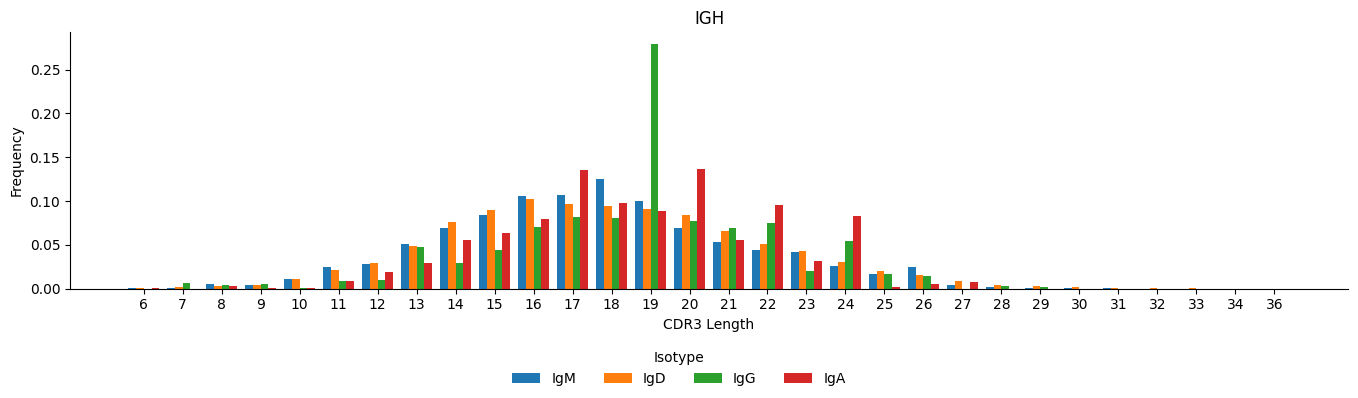

In [12]:
# Распределение длин CDR3 (в аминокислотах) по изотипам.
cdr3_len_distribs = stats.cdr3_length_distributions(
    clonosets_iso, cl_filter=func_filter, cpu=2, count_by_freq=True,
    seq_type="aa", table="long", zero_fill=True)
rsplot.cdr3_length_distributions(cdr3_len_distribs, metadata=metadata_bcr, group="isotype", height=4)

In [13]:
# Мода и средняя длина CDR3 по изотипам (по таблице распределения).
d = cdr3_len_distribs.merge(metadata_bcr)
mode_len = d.loc[d.groupby("isotype", observed=True)["freq"].idxmax(), ["isotype", "cdr3_length"]].set_index("isotype")
mean_len = d.assign(w=d["cdr3_length"] * d["freq"]).groupby("isotype", observed=True)[["w", "freq"]].sum()
mode_len["mean_cdr3_length"] = (mean_len["w"] / mean_len["freq"]).round(2)
mode_len.rename(columns={"cdr3_length": "mode_cdr3_length"})

,mode_cdr3_length,mean_cdr3_length
isotype,,
IgM,18,17.68
IgD,16,17.88
IgG,19,18.65
IgA,20,18.58


## Segment usage

### V-usage

In [14]:
v_usage = stats.calc_segment_usage(clonosets_all, segment="v", cl_filter=func_filter, table="long", cpu=2)
v_table = (100 * v_usage.merge(metadata_bcr).pivot_table(index="v", columns="isotype", values="usage", observed=True))
v_table = v_table.sort_values("all", ascending=False).round(1)
print("V гены, доля UMI, %")
v_table.head(12)

Using 2 cores
CalcSegmentUsage |##################################################| 5/5 calcultaion(s) processed
V гены, доля UMI, %


isotype,all,IgM,IgD,IgG,IgA
v,,,,,
IGHV3-23,14.0,15.1,16.9,9.0,14.5
IGHV3-33,8.5,4.6,4.4,20.6,6.5
IGHV2-5,7.6,7.6,4.1,11.1,7.0
IGHV4-59,7.2,8.2,6.8,6.6,6.1
IGHV1-18,6.6,6.3,5.8,8.6,5.3
IGHV3-21,5.4,6.0,6.4,4.1,4.3
IGHV3-30-3,4.0,2.3,4.2,5.2,6.4
IGHV4-39,3.4,3.6,3.7,2.1,4.5
IGHV3-15,3.1,5.3,2.8,0.8,1.3


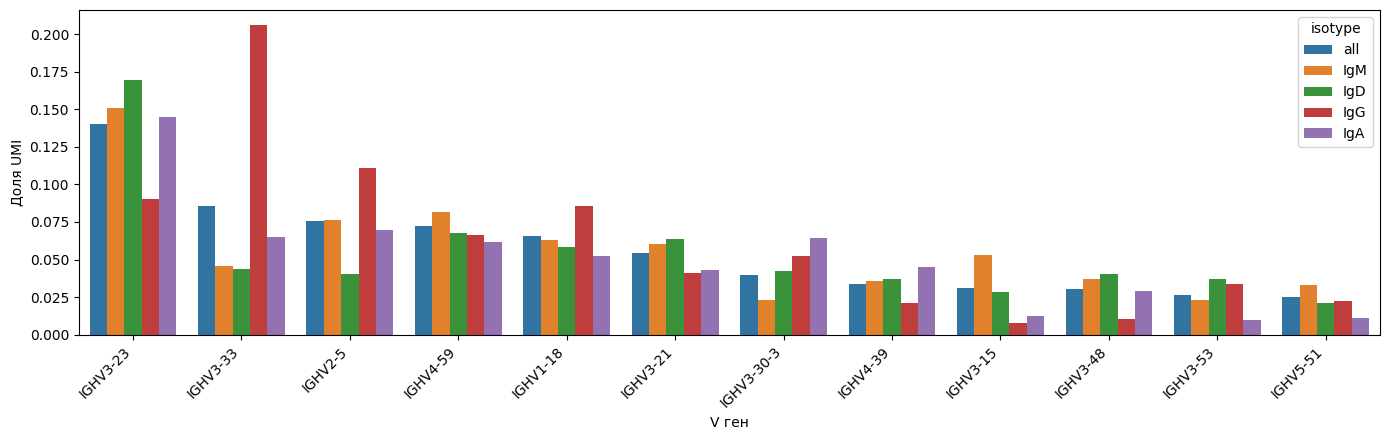

In [15]:
# 12 самых частых V генов во всем IGH и их доли в каждом изотипе.
top_v = v_table.head(12).index
plot_df = v_usage[v_usage["v"].isin(top_v)].merge(metadata_bcr)
plt.figure(figsize=(14, 4.5))
sns.barplot(data=plot_df, x="v", y="usage", hue="isotype", order=top_v)
plt.xticks(rotation=45, ha="right"); plt.ylabel("Доля UMI"); plt.xlabel("V ген")
plt.tight_layout(); plt.show()

In [16]:
# То же по семействам V генов (IGHV1, IGHV3, ...).
v_usage["v_family"] = v_usage["v"].str.extract(r"^(IGHV\d+)")[0]
fam = (100 * v_usage.merge(metadata_bcr).groupby(["v_family", "isotype"], observed=True)["usage"].sum().unstack())
fam.sort_values("all", ascending=False).round(1)

isotype,all,IgM,IgD,IgG,IgA
v_family,,,,,
IGHV3,55.2,53.9,58.4,55.0,54.5
IGHV1,16.4,16.1,16.5,16.5,17.0
IGHV4,14.1,14.6,14.7,10.7,17.5
IGHV2,10.4,10.1,6.6,15.0,9.7
IGHV5,3.3,4.4,3.2,2.8,1.2
IGHV6,0.6,1.0,0.6,0.0,0.2
IGHV7,0.0,0.0,0.0,0.0,0.0


### J-usage

In [17]:
j_usage = stats.calc_segment_usage(clonosets_all, segment="j", cl_filter=func_filter, table="long", cpu=2)
j_table = (100 * j_usage.merge(metadata_bcr).pivot_table(index="j", columns="isotype", values="usage", observed=True))
j_table.sort_values("all", ascending=False).round(1)

Using 2 cores
CalcSegmentUsage |##################################################| 5/5 calcultaion(s) processed


isotype,all,IgM,IgD,IgG,IgA
j,,,,,
IGHJ4,45.7,52.2,47.1,35.1,42.0
IGHJ6,27.1,17.3,27.1,47.4,22.0
IGHJ3,13.8,15.0,11.5,12.0,16.7
IGHJ5,10.0,11.8,11.5,4.0,12.5
IGHJ2,2.1,2.3,1.8,1.4,3.1
IGHJ1,1.3,1.4,0.9,0.2,3.7


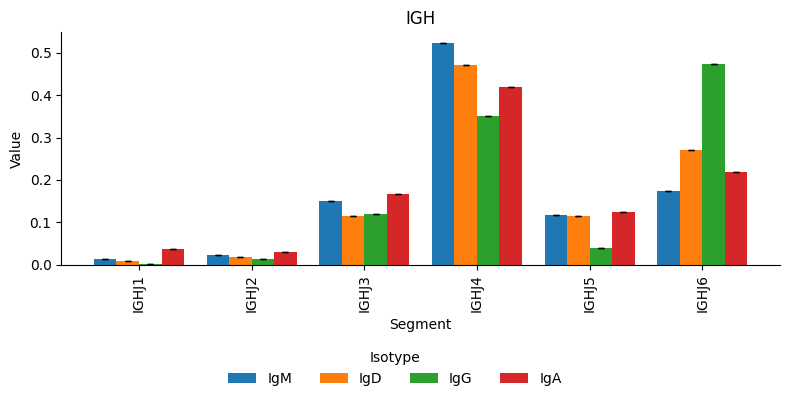

In [18]:
rsplot.segment_usage(j_usage[j_usage["sample_id"] != whole_id], metadata=metadata_bcr, group="isotype",
                     plot_type="barplot", height=4)

### C-usage (изотипы)

In [19]:
# Использование C генов во всем репертуаре IGH (функциональные клонотипы, доля UMI).
c_usage = stats.calc_segment_usage(clonosets_whole, segment="c", cl_filter=func_filter, table="long", cpu=2)
c_seg = [c for c in c_usage.columns if c not in ("sample_id", "chain", "usage")][0]
c_usage = c_usage.sort_values("usage", ascending=False)
c_usage.assign(usage_pct=(100 * c_usage["usage"]).round(1))[[c_seg, "usage_pct"]]

Using 2 cores
CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


,c,usage_pct
9,IGHM,40.9
3,IGHD,21.6
4,IGHG1,18.6
1,IGHA1,11.5
6,IGHG3,3.3
2,IGHA2,2.7
5,IGHG2,1.4
7,IGHG4,0.0
0,<NA>,0.0
8,IGHGP,0.0


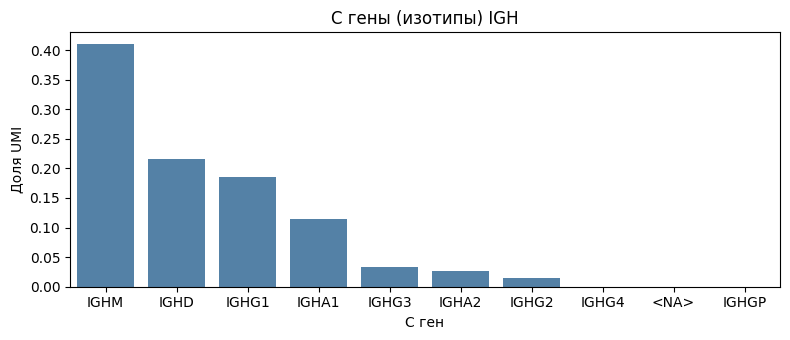

In [20]:
plt.figure(figsize=(8, 3.5))
sns.barplot(data=c_usage, x=c_seg, y="usage", color="steelblue")
plt.ylabel("Доля UMI"); plt.xlabel("C ген"); plt.title("C гены (изотипы) IGH")
plt.tight_layout(); plt.show()

## Convergence

Convergence = число разных CDR3 на уровне нуклеотидов / число разных CDR3 на уровне аминокислот. Считаем на одинаковой глубине для всех изотипов. В BCR на это число влияют еще и синонимичные соматические мутации внутри одного клона.

In [21]:
convergence = stats.calc_convergence(clonosets_iso, cl_filter=downsample_filter, seed=42, cpu=2, verbose=True)
convergence.merge(metadata_bcr)[["isotype", "convergence", "convergence_v", "convergence_vj"]].round(4)

CalcConvergence settings: seed=42, downsample=12500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 4/4 calcultaion(s) processed
Using 2 cores
CalcConvergence |##################################################| 4/4 calcultaion(s) processed


,isotype,convergence,convergence_v,convergence_vj
0,IgM,1.0015,1.0015,1.0015
1,IgD,1.0009,1.0008,1.0008
2,IgG,1.1008,1.1008,1.1008
3,IgA,1.0573,1.0571,1.0567


## Diversity stats

**Разнообразие внутри изотипа** на одинаковой глубине (DOWNSAMPLE UMI, 3 повтора субсэмплирования, повторы усредняем). `diversity` это число разных клонотипов, `clonality` показывает, насколько репертуар занят немногими крупными клонами, `berger_parker` это доля самого крупного клонотипа, `d50` доля клонотипов, которые вместе дают половину молекул.

In [22]:
diversity_iso = stats.calc_diversity_stats(clonosets_iso, cl_filter=downsample_filter, seed=123, cpu=2,
                                           iterations=3, drop_small_samples=False, verbose=True)
div_cols = [c for c in ["diversity", "shannon_wiener", "norm_shannon_wiener", "clonality", "chao1",
                        "berger_parker", "d50", "goods_coverage"] if c in diversity_iso.columns]
diversity_iso_mean = diversity_iso.groupby("sample_id")[div_cols].mean().reset_index().merge(metadata_bcr)
diversity_iso_mean[["isotype"] + div_cols].round(4)

CalcDiversityStats settings: seed=123, downsample=12500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 4/4 calcultaion(s) processed
Using 2 cores
CalcDiversityStats |##################################################| 4/4 calcultaion(s) processed


,isotype,diversity,shannon_wiener,norm_shannon_wiener,clonality,chao1,berger_parker,d50,goods_coverage
0,IgA,1008.0,5.8120,0.8404,0.1596,3284.5217,0.0276,0.0833,0.9551
1,IgD,10418.0,9.1910,0.9935,0.0065,33680.7897,0.0004,0.4001,0.3123
2,IgG,1133.0,6.1038,0.8679,0.1321,2774.5882,0.0295,0.0927,0.9622
3,IgM,8516.0,8.4706,0.9360,0.0640,31935.7096,0.0110,0.2661,0.4252


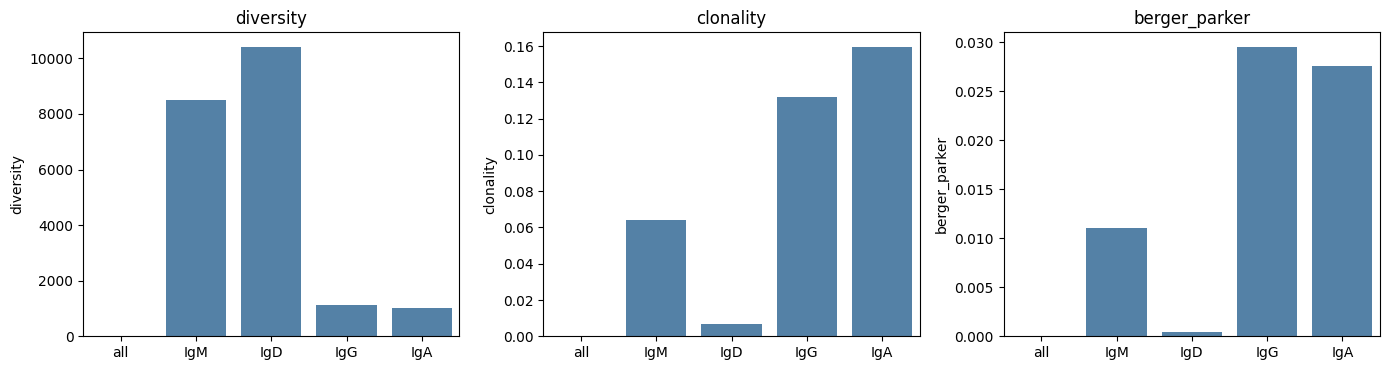

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, metric in zip(axes, ["diversity", "clonality", "berger_parker"]):
    sns.barplot(data=diversity_iso_mean, x="isotype", y=metric, ax=ax, color="steelblue")
    ax.set_title(metric); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [24]:
# Разнообразие всего репертуара IGH (без даунсэмплинга, образец один, сравнивать не с чем).
diversity_whole = stats.calc_diversity_stats(clonosets_whole, cl_filter=func_filter, iterations=1, cpu=2)
diversity_whole[div_cols].round(4)

CalcDiversityStats: for the most honest comparison, use a filter with equal downsampling for all samples. This is preferred to top=N filters and much preferred to calculations without normalization.
CalcDiversityStats settings: seed=None, downsample=None, top=None, iterations=1
Using 2 cores
CalcDiversityStats |##################################################| 1/1 calcultaion(s) processed


,diversity,shannon_wiener,norm_shannon_wiener,clonality,chao1,berger_parker,d50,goods_coverage
0,36416.0,9.3256,0.8879,0.1121,73101.5018,0.0072,0.0671,0.7272


In [25]:
# Самые крупные клонотипы всего репертуара: изотип, V, J, CDR3 и доля UMI.
v_col = next(c for c in clones.columns if c.startswith("allVHits"))
j_col = next(c for c in clones.columns if c.startswith("allJHits"))
top_clones = clones.sort_values("uniqueMoleculeCount", ascending=False).head(15).copy()
top_clones["v"] = top_clones[v_col].str.split(r"[*(,]").str[0]
top_clones["j"] = top_clones[j_col].str.split(r"[*(,]").str[0]
top_clones["umi_%"] = (100 * top_clones["uniqueMoleculeCount"] / clones["uniqueMoleculeCount"].sum()).round(2)
top_clones[["aaSeqCDR3", "v", "j", "c_gene", "isotype", "uniqueMoleculeCount", "umi_%"]]

,aaSeqCDR3,v,j,c_gene,isotype,uniqueMoleculeCount,umi_%
1,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,IGHG3,IgG,645,0.71
0,CAHSPASQGHFLMTFGGLIIPHFDSW,IGHV2-5,IGHJ4,IGHM,IgM,445,0.49
5,CARDRRTGIWSGYGYMDVW,IGHV3-33,IGHJ6,IGHG1,IgG,370,0.41
17,CARSDMLRFVEWTGSYQRFHMDVW,IGHV4-61,IGHJ6,IGHA1,IgA,353,0.39
3,CARDPNYDFWSGGDMNVW,IGHV3-21,IGHJ6,IGHM,IgM,353,0.39
4,CTTDLDYYDSSGYRFDCW,IGHV3-15,IGHJ4,IGHM,IgM,339,0.37
2,CAHSSDIIGGSWGFGMDVW,IGHV2-5,IGHJ6,IGHG1,IgG,255,0.28
10,CARGGDPRVVVAATDAFDFW,IGHV1-46,IGHJ3,IGHA1,IgA,253,0.28
11,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,IGHG3,IgG,227,0.25
13,CTKDPLSPWFGNFEIFDYW,IGHV3-23,IGHJ4,IGHG1,IgG,225,0.25


In [26]:
# Доля одиночных клонотипов (1 UMI) по изотипам.
singles = clones.assign(single=clones["uniqueMoleculeCount"] == 1).groupby("isotype")["single"].mean()
(100 * singles).round(1).rename("singletons_%").to_frame()

,singletons_%
isotype,
IgA,56.9
IgD,74.8
IgE,100.0
IgG,49.2
IgM,64.7
unknown,100.0


## Rarefaction

Для всего IGH и для каждого изотипа считаем, сколько разных клонотипов найдется при разной глубине (по оси X число UMI в подвыборке, по оси Y число разных клонотипов). Если кривая выходит на плато, новые молекулы почти не дают новых клонотипов.

Using 2 cores
CalcRarefactionPoints |##################################################| 5/5 calcultaion(s) processed


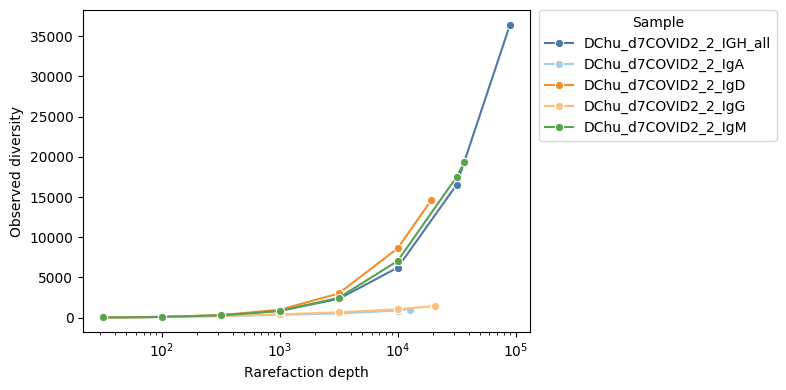

In [27]:
rarefaction_points = stats.calc_rarefaction_curve(clonosets_all, cl_filter=func_filter, iterations=3, seed=100, cpu=2)
rsplot.rarefaction_curve(rarefaction_points, log_x=True, aspect=2, height=4)

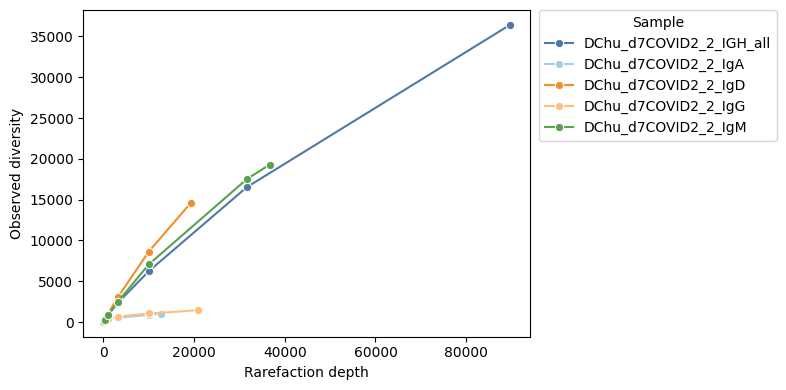

In [28]:
rsplot.rarefaction_curve(rarefaction_points, log_x=False, aspect=2, height=4)

## Сходство изотипов (вместо бета-разнообразия между людьми)

В семинаре бета-разнообразие сравнивало разных людей. У нас один человек, поэтому сравниваем изотипы между собой. Совпадение `aaV` (одинаковая CDR3aa и V ген) у IgM и IgG, например, скорее всего означает один и тот же B-клеточный клон, часть которого переключила класс. MDS на 4 точках смысла не имеет, поэтому смотрим только матрицы.

In [29]:
f2 = beta.metrics(clonosets_iso, cl_filter=downsample_filter, overlap_type="aaV", metrics=["f2"], cpu=2)
f2

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV
Reading clonosets |##################################################| 4/4 sample(s) processed
Using 2 cores
Intersecting clonosets |##################################################| 6/6 pairs processed


sample2,DChu_d7COVID2_2_IgA,DChu_d7COVID2_2_IgD,DChu_d7COVID2_2_IgG,DChu_d7COVID2_2_IgM
sample1,,,,
DChu_d7COVID2_2_IgA,1.000000,0.000000,0.049073,0.008398
DChu_d7COVID2_2_IgD,0.000000,1.000000,0.000368,0.166379
DChu_d7COVID2_2_IgG,0.049073,0.000368,1.000000,0.029772
DChu_d7COVID2_2_IgM,0.008398,0.166379,0.029772,1.000000


In [30]:
# Число общих клонотипов (CDR3aa + V) между изотипами, без даунсэмплинга.
shared = beta.metrics(clonosets_iso, cl_filter=func_filter, overlap_type="aaV",
                      metrics=["number_of_intersecting_clonotypes"], cpu=2)
shared

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV
Reading clonosets |##################################################| 4/4 sample(s) processed
Using 2 cores
Intersecting clonosets |##################################################| 6/6 pairs processed


sample2,DChu_d7COVID2_2_IgA,DChu_d7COVID2_2_IgD,DChu_d7COVID2_2_IgG,DChu_d7COVID2_2_IgM
sample1,,,,
DChu_d7COVID2_2_IgA,722.0,2.0,18.0,4.0
DChu_d7COVID2_2_IgD,2.0,14427.0,2.0,5445.0
DChu_d7COVID2_2_IgG,18.0,2.0,927.0,9.0
DChu_d7COVID2_2_IgM,4.0,5445.0,9.0,18778.0


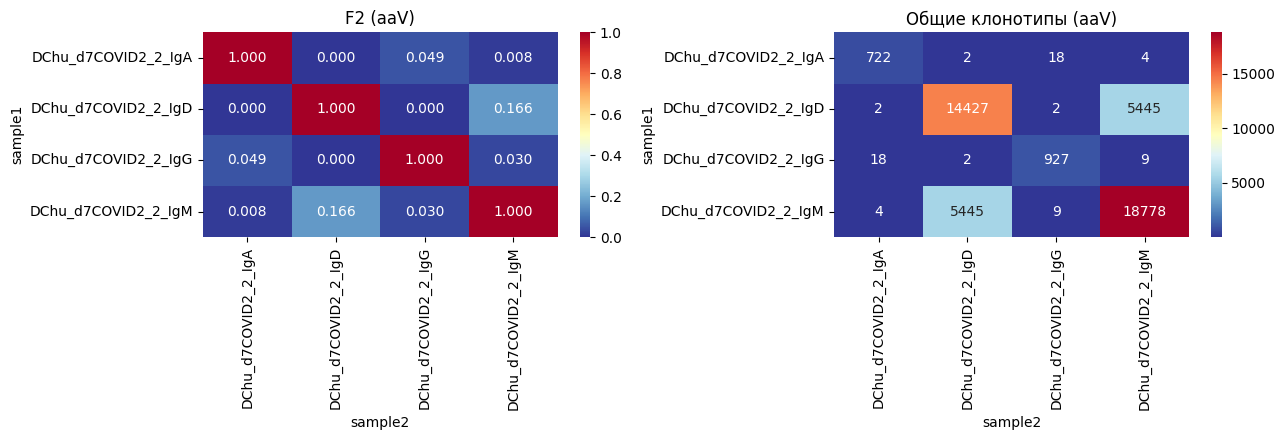

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(f2, annot=True, fmt=".3f", cmap="RdYlBu_r", ax=axes[0]); axes[0].set_title("F2 (aaV)")
sns.heatmap(shared, annot=True, fmt=".0f", cmap="RdYlBu_r", ax=axes[1]); axes[1].set_title("Общие клонотипы (aaV)")
plt.tight_layout(); plt.show()

## Clustering

**Клональные линии.** Соединяем клонотипы с одинаковым V геном, у которых CDR3aa отличается не больше чем на 1 аминокислоту. В BCR такие кластеры часто это один клон с соматическими мутациями. Берем все изотипы на одинаковой глубине и смотрим, есть ли кластеры, в которых встречаются разные изотипы (признак переключения класса).

In [32]:
clusters = clustering.Clusters()
clusters.read_from_clonosets_df(clonosets_iso, cl_filter=downsample_filter)
clusters.create_clusters(overlap_type="aaV", mismatches=1)
clusters.add_metadata(metadata_bcr)
clusters_df = clusters.as_dataframe()
clusters_df.head()

Pooled 21075 clonotypes from 4 samples
Nodes list created: 21075 nodes
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Find neighbour clonotypes |##################################################| 848/848 tasks processed
found 6433 edges
-----------------------------
NexworkX graph created
Found 2322 clusters (2 or more nodes) and 15799 single nodes. Total: 18121


,cluster_no,node_id,cdr3aa,v,j,cdr3nt,sample_id,freq,count,isotype,n_neighbours
0,0,12,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGACCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,DChu_d7COVID2_2_IgG,0.01080,135,IgG,60
1,0,245,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGGCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,DChu_d7COVID2_2_IgG,0.00272,34,IgG,60
2,0,9619,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,DChu_d7COVID2_2_IgG,0.00008,1,IgG,60
3,0,4,CARDRRTGIWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGTCGTACTGGTATTTGGAGTGGTTATGGCTACA...,DChu_d7COVID2_2_IgG,0.01584,198,IgG,60
4,0,123,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,DChu_d7COVID2_2_IgG,0.00408,51,IgG,60


In [33]:
cluster_properties = clusters.properties()
cluster_properties.head(15)

Using all available worker processes by default. Set cpu=1 or another integer to change this.
Calculating cluster properties |##################################################| 18121/18121 clusters processed


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
0,0,cluster_0,70,1846,2400,4,0.764389,3.100000,CARDRRTGLWSGYGYMDVW,TGTGCGAGAGATCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,IGHV3-33,IGHJ6
1,1,cluster_1,40,225,454,6,0.288462,4.550000,CAKLQGIFWLWQPNRAGGADYW,TGTGCGAAACTTCAGGGAATATTTTGGTTGTGGCAACCCAACCGGG...,IGHV3-30,IGHJ4
2,2,cluster_2,27,288,510,3,0.820513,2.185185,CAHRPGIALVGAGAFRFDPW,TGTGCACACAGGCCGGGTATAGCACTGGTTGGTGCTGGTGCGTTCC...,IGHV2-5,IGHJ5
3,3,cluster_3,19,80,387,4,0.467836,3.052632,CARFVRGAFPPYYYYMDVW,TGTGCGAGATTTGTACGTGGAGCTTTTCCCCCCTACTACTACTACA...,IGHV1-18,IGHJ6
4,4,cluster_4,17,76,98,3,0.558824,2.470588,CARSPRRFDFWSGFYSYYFDYW,TGTGCGAGATCCCCCCGGCGTTTCGATTTTTGGAGTGGTTTTTATT...,IGHV3-21,IGHJ4
5,5,cluster_5,14,48,250,3,0.527473,2.571429,CAHRSGIAVAGTGVFDYW,TGTGCACACAGATCCGGTATAGAAGTGGCTGGTACGGGGGTTTTTG...,IGHV2-5,IGHJ4
6,6,cluster_6,14,91,266,1,1.000000,1.000000,CARDPNYDFWSGGDMNVW,TGTGCGAGAGACCCCAATTACGATTTTTGGAGTGGAGGGGACATGA...,IGHV3-21,IGHJ6
7,7,cluster_7,13,78,188,1,1.000000,1.000000,CARDRWTPDVPDALDYW,TGTGCGAGAGATCGGTGGACTCCTGATGTACCAGACGCCCTTGACT...,IGHV3-30-3,IGHJ4
8,8,cluster_8,13,78,254,1,1.000000,1.000000,CARRERFWSGYYTGREMIAFDIW,TGTGCGAGACGGGAGAGATTTTGGAGTGGTTATTATACCGGTAGGG...,IGHV1-18,IGHJ3
9,9,cluster_9,13,45,201,4,0.576923,3.230769,CARTQKEVTIFGTFYYAMDVW,TGTGCACGGACCCAAAAAGAGGTTACGATTTTTGGAACCTTCTACT...,IGHV2-26,IGHJ6


In [34]:
# Сколько кластеров (2 и больше клонотипов) содержат клонотипы разных изотипов.
iso_col = "isotype" if "isotype" in clusters_df.columns else "sample_id"
multi = clusters_df.groupby("cluster_no").filter(lambda x: len(x) >= 2)
n_iso = multi.groupby("cluster_no")[iso_col].nunique()
print("Кластеров из 2 и больше клонотипов:", n_iso.size)
print("Из них с разными изотипами:", (n_iso > 1).sum())
mixed = multi[multi["cluster_no"].isin(n_iso[n_iso > 1].index)]
mixed.groupby("cluster_no")[iso_col].agg(lambda x: ", ".join(sorted(set(map(str, x))))).value_counts().rename("clusters").to_frame()

Кластеров из 2 и больше клонотипов: 2322
Из них с разными изотипами: 1803


,clusters
isotype,
"IgD, IgM",1770
"IgA, IgG",20
"IgG, IgM",6
"IgA, IgG, IgM",3
"IgD, IgG",3
"IgA, IgM",1


In [35]:
clusters

Clusters state:
  Completed: clonotypes read, clusters created, metadata added
Clonotypes:
    source: clonosets_df
    clonotypes: 21075
    samples: 4
    input_samples: 4
    filter:
      name: default_filter
      functionality: f
      downsample_size: 12500
      top: None
      by_umi: True
      mix_tails: False
      seed: 100
      count_threshold: None
      unweight: False
      recount_fractions: True
      white_list: []
      black_list: []
      pool_by: 
      convert: True
      ignore_small_clonosets: False
      retain_alleles: False
Graph: 21075 nodes and 6433 edges
Clusters: 2322 clusters (2 or more nodes) and 15799 single nodes. Total: 18121
Clustering parameters:
    method: mismatches
    overlap_type: aaV
    mismatches: 1
Metadata columns: isotype
Node Pgen: not calculated
ALICE: not calculated

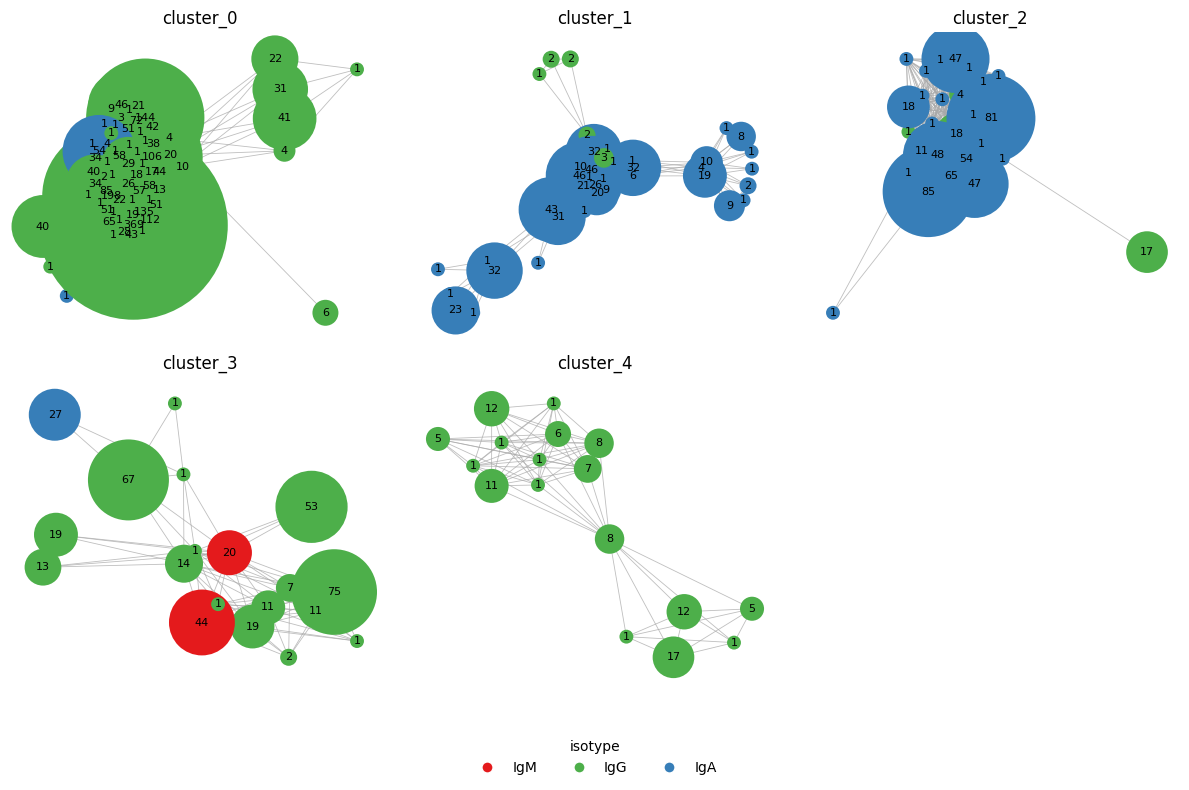

In [36]:
# Рисуем 5 самых больших кластеров, цвет это изотип, размер вершины это число молекул.
clusters.plot_cluster(range(0, 5), color="isotype", label="count", log_scaled=False, size="count", linear_scale=50)

## Выводы

**Коротко.** Образец один (PBMC), поэтому вместо групп людей сравнивали изотипы тяжелой цепи: IgM и IgD (в основном наивные B-клетки) против IgG и IgA (клетки, которые уже встретили антиген и переключили класс).
- По числу молекул больше всего IgM и IgD (63%), но репертуар IgG и IgA устроен совсем по-другому: в нем мало клонотипов и они очень крупные, в среднем 12-14 UMI на клонотип против 1,3-1,9 у IgM и IgD.
- На одинаковой глубине IgG и IgA в 7-9 раз менее разнообразны и в 2-25 раз клональнее, чем IgM и IgD, их rarefaction кривые почти вышли на плато. Похоже на активный ответ с размножением отдельных клонов (плазмобласты).
- Самый крупный клон всего репертуара (IGHV3-33, IGHJ6, CDR3 CARDRRTGLWSGYGYMDVW) это IgG1 и IgG3, у него много вариантов с соматическими мутациями (самый большой кластер, 70 клонотипов).
- Общие клонотипы IgM и IgD это скорее одни и те же наивные клетки (они несут IgM и IgD одновременно), а следы переключения класса видны между IgG и IgA и в нескольких кластерах IgM+IgG.
- Главные ограничения: образец один и нет контроля до болезни, считали по молекулам РНК (у плазмобластов РНК иммуноглобулина намного больше, чем у покоящихся клеток), мутации напрямую не считали.

**Как читать графики.** На графике длин CDR3 по оси X длина в аминокислотах, по Y доля клонотипов такой длины, цвет это изотип. На графиках V и J по X ген, по Y его доля молекул (UMI) в изотипе. На графиках разнообразия по X изотип, по Y значение метрики. На rarefaction по X число UMI в подвыборке, по Y сколько разных клонотипов найдено, если кривая выходит на плато значит почти все клонотипы уже найдены. На тепловых картах каждая клетка это пара изотипов, F2 показывает сходство с учетом частот, вторая карта число общих клонотипов (одинаковые CDR3aa и V). На графе кластеров вершина это клонотип, число в ней это количество молекул, ребро соединяет клонотипы с одинаковым V и CDR3, отличающимися на 1 аминокислоту, цвет это изотип.

### Подробно

**Обработка.** MiXCR выровнял 92,2% ридов, 91,6% вошли в клонотипы. Предупреждения связаны с фильтрацией UMI (выброшено 9,6% ридов из маленьких UMI групп), это нормально. Получилось 37516 клонотипов IGH (36416 функциональных) и 90924 молекулы (UMI). IGK и IGL нет, потому что протокол амплифицирует только тяжелую цепь.

**Изотипы.** По молекулам: IgM 41,1%, IgD 21,8%, IgG 23,1% (IgG1 18,4%, IgG3 3,2%, IgG2 1,4%), IgA 14,0% (IgA1 11,3%, IgA2 2,7%), IgE практически нет. По клонотипам картина другая: у IgM 19899 клонотипов, у IgD 15062, а у IgG всего 1510 и у IgA 1039. То есть в IgG и IgA на один клонотип приходится 12-14 молекул, а в IgM и IgD 1,3-1,9. Доля клонотипов из одной молекулы 75% у IgD и 65% у IgM против 49-57% у IgG и IgA.

**Выбор downsample.** Для сравнения изотипов взяли 12500 UMI, это самый маленький изотип (IgA, 12713 функциональных UMI) с округлением вниз, так ни один изотип не выпадает.

**CDR3.** У IgG и IgA CDR3 длиннее (в среднем 18,6 аминокислот против 17,7-17,9 у IgM и IgD, мода 19-20 против 16-18) и вставки больше (15,1-16,5 нт против 11,3-11,5). CDR3 без вставок почти нет ни в одном изотипе (0-1,4%), в отличие от TCR новорожденных. CDR3 у IgG в среднем заряжен положительно (+0,23), у остальных изотипов отрицательно. В IgG и IgA всего около тысячи клонотипов, и среди них есть крупные клональные линии со множеством мутантных вариантов, поэтому их свойства могут сильно зависеть от нескольких клонов. Например, у самой большой линии IgG (70 вариантов в кластере) CDR3 длиной 19 аминокислот с IGHJ6, самым длинным J геном.

**V и J сегменты.** В целом лидирует IGHV3-23 (14%), семейство IGHV3 дает больше половины репертуара во всех изотипах (54-58%). При этом у IgG сильно выделяются IGHV3-33 (20,6% против 4,6% у IgM) и IGHV2-5 (11,1% против 7,6%), а среди J у IgG IGHJ6 47,4% против 17,3% у IgM. Это не общий сдвиг, а след крупных клонов: самый большой клон IgG как раз IGHV3-33 с IGHJ6.

**Convergence.** У IgM и IgD почти 1 (1,0015 и 1,0009), а у IgG 1,10 и у IgA 1,06. В TCR высокая convergence у недоношенных объяснялась зародышевыми последовательностями, а тут причина другая: внутри одного размножившегося B-клона идут соматические мутации, часть из них синонимичные, и одна и та же аминокислотная CDR3 записана разными нуклеотидными вариантами. То есть в BCR эта метрика скорее показывает мутации в крупных клонах.

**Разнообразие (12500 UMI).** IgD самый разнообразный: 10418 клонотипов, нормированный Шеннон 0,994, clonality 0,007, крупнейший клон 0,04%, это типично для наивных клеток. IgM чуть менее разнообразный (8516 клонотипов, clonality 0,064, крупнейший клон 1,1%), видимо в нем есть и наивные клетки, и IgM клетки памяти или плазмобласты. IgG и IgA на той же глубине дают всего 1133 и 1008 клонотипов, clonality 0,13 и 0,16, крупнейший клон около 3%, и половину всех молекул дают всего 8-9% клонотипов. Goods coverage у IgG и IgA 0,96, то есть почти все клонотипы найдены, а у IgM и IgD 0,31-0,43. Весь репертуар IGH без даунсэмплинга: 36416 клонотипов, крупнейший клон 0,72% UMI.

**Rarefaction.** Кривые IgG и IgA почти сразу выходят на плато (около 1000-1500 клонотипов), а кривые IgM, IgD и всего IGH растут почти линейно. Значит переключенные клетки представлены небольшим числом крупных клонов, а наивный пул гораздо больше, чем мы смогли прочитать.

**Крупные клоны.** Из 15 самых крупных клонотипов 10 переключенные (IgG1, IgG3, IgA1, IgA2). Самый крупный это CARDRRTGLWSGYGYMDVW (IGHV3-33, IGHJ6, IgG3, 0,71% всех молекул), и он же встречается в списке еще несколько раз: как IgG1 и IgG3 и с заменой одной аминокислоты (CARDRRTGIWSGYGYMDVW). В таблице это разные строки, потому что MiXCR собирает клонотипы с учетом C гена и всей последовательности от CDR1 до FR4, а на деле это одна клональная линия.

**Сходство изотипов.** Больше всего общих клонотипов у IgM и IgD: 5445 общих, F2 0,17. Это ожидаемо, потому что наивные B-клетки одновременно несут IgM и IgD, то есть это одни и те же клетки, а не переключение класса. Между переключенными изотипами общих меньше, но они есть: IgG и IgA 18 общих (F2 0,049), IgG и IgM 9 (F2 0,030), IgA и IgM 4. С IgD у IgG и IgA почти ничего общего (2 клонотипа). Это похоже на то, что одни и те же клоны после активации переключаются и в IgG, и в IgA.

**Кластеры.** Кластеры строили на подвыборках по 12500 UMI из каждого изотипа. Из 2322 кластеров (2 и больше клонотипов) в 1803 встречаются разные изотипы, но почти все это пары IgD и IgM (1770), по той же причине, что выше. Кластеров с переключением класса немного: 20 IgA и IgG, 6 IgG и IgM, 3 сразу IgA, IgG и IgM. Пять самых больших кластеров в основном из переключенных клеток (IgG и IgA). Самый большой (70 клонотипов, 2400 молекул) это та самая линия IGHV3-33 в IgG с несколькими IgA. В кластере 3 вместе IgM и IgG, то есть видно, как один клон есть и до переключения, и после. Много близких вариантов внутри одного кластера это как раз соматические гипермутации.

**Ограничения.** Один образец без контроля (например другого человека или того же человека в другой момент), поэтому нельзя сказать, чем этот репертуар отличается от обычного. Считали по молекулам РНК, а у плазмобластов РНК иммуноглобулина в разы больше, чем у покоящихся B-клеток, поэтому доли IgG и IgA по молекулам не равны долям клеток. Есть только тяжелая цепь, пары с легкими цепями неизвестны. Соматические мутации напрямую не считали (для этого нужно сравнивать последовательности с зародышевыми V генами). Деление на изотипы искусственное, это не независимые образцы.